# Malaria Cell Image Classification

## Image Preparation and Augmentation
Reproducible preparation for comparing an SVM and CNN. Target: `Parasitized=1`, `Uninfected=0`

### Design and references
We decided to keep all cells from each patient in a single partition so that evaluation measures performance on previously unseen patients. Cells from the same patient can share staining and imaging characteristics; allowing them into both training and testing could inflate performance. We also apply color normalization and training-only augmentation to address variation in image appearance. We use approximately 70/15/15 training/validation/test partitions, with patient grouping taking priority over exact image counts. The split is made **before** fitting transformations or generating augmented images.

Sources: [NLM dataset and official patient mappings](https://lhncbc.nlm.nih.gov/LHC-research/LHC-projects/image-processing/malaria-datasheet.html), [Rajaraman et al. 2018](https://doi.org/10.7717/peerj.4568). The proposal's Dong (2017) link actually points to [EMFE (2026)](https://arxiv.org/abs/2608.24793)

This data preparation pipeline implements our own preparation choices, not a replication of either paper.

In [9]:
from pathlib import Path
import csv, json, re
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from skimage.color import rgb2lab, lab2rgb
from skimage.feature import hog
from IPython.display import display

ROOT = Path(".") if Path.cwd().name == "final_project" else Path("final_project")
DATA = ROOT / 'cell_images'
OUT = ROOT / 'artifacts'
OUT.mkdir(exist_ok=True)
SEED = 42656
SIZE = (128, 128)
AUGMENTED_COPIES = 1  # one additional view per training cell; zero disables expansion

### Load images and establish patient identity
We established patient identity by matching image filenames to patient identifiers in the NLM patientid_cellmapping CSV files and combining camera-specific entries from the same patient. We used these identifiers only to keep each patient's cells in one partition, not as model features. 

The split also retained approximately balanced classes, with parasitized cells making up 49.7% of training images, 50.8% of validation images and 50.6% of test images. All images passed a readability check during initial preparation. This cell now builds the image-to-patient records without reopening the images; it checks that each filename has a patient mapping.


In [10]:
mapping = {}
for cls in ['parasitized', 'uninfected']:
    path = ROOT / 'metadata' / f'patientid_cellmapping_{cls}.csv'
   
    # NLM layout: patient ID followed by a variable number of cell filenames.
    with path.open(newline='', encoding='utf-8-sig') as f:
        for row in csv.reader(f):
            if len(row) < 2:
                continue
            patient_match = re.search(r'P[0-9]+', row[0])
            patient = patient_match.group(0) if patient_match else row[0].strip()
            for item in row[1:]:
                match = re.search(r"[A-Za-z0-9_]+[.]png", item)
                name = match.group(0) if match else ""
                if not name.lower().endswith('.png'):
                    continue
                key = (cls.lower(), name)
                if key in mapping and mapping[key] != patient:
                    raise ValueError(f'Ambiguous patient for {name}')
                mapping[key] = patient

rows = []
for class_name, label in [('Uninfected', 0), ('Parasitized', 1)]:
    for path in sorted((DATA / class_name).glob('*.png')):
        patient = mapping.get((class_name.lower(), path.name))
        if patient is None:
            raise ValueError(f'No patient mapping for {path.name}')
        rows.append(dict(path=path.relative_to(ROOT).as_posix(), label=label,
                         class_name=class_name, patient_id=patient))
manifest = pd.DataFrame(rows)
if manifest.empty:
    raise ValueError('No images found')
display(manifest.groupby('class_name').agg(images=('path', 'size'), patients=('patient_id', 'nunique')))


,images,patients
class_name,,
Parasitized,13779,150
Uninfected,13779,200


### 3.1 Training, validation and testing split
We chose an approximately 70/15/15 allocation to give both models most of the available patients for learning while reserving separate data for model selection and final evaluation. The validation set supports choices such as preprocessing, augmentation and model hyperparameters; the test set is reserved for evaluation after those choices are fixed.

This is a practical starting allocation, not a ratio shown to be optimal. A 50/30/20 allocation would provide larger validation and test sets but leave fewer patients for fitting the models. We prioritized a larger training set, particularly for the CNN, while retaining about 28 patients in each held-out set. Patient counts matter here because cells from one patient are correlated. If validation results vary substantially across patient groups, grouped cross-validation within the training data can help assess model-selection stability without using the test set.

We implement this allocation with seven stratified patient-group folds: five for training, one for validation and one for testing. The nominal ratio is therefore **71.4%/14.3%/14.3%**, rather than exactly 70/15/15. Because patients contribute different numbers of cells, the actual image fractions are **71.77%/14.13%/14.09%**: 19,779 training images from 144 patients, 3,895 validation images from 28 patients and 3,884 test images from 28 patients.

In [12]:
splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
manifest['fold'] = -1
for fold, (_, held) in enumerate(splitter.split(manifest, manifest.label, manifest.patient_id)):
    manifest.loc[held, 'fold'] = fold
manifest['split'] = manifest.fold.map(lambda f: 'test' if f == 0 else 'validation' if f == 1 else 'train')
parts = {s: manifest[manifest.split == s].reset_index(drop=True) for s in ['train','validation','test']}
for a, b in [('train','validation'), ('train','test'), ('validation','test')]:
    assert set(parts[a].patient_id).isdisjoint(parts[b].patient_id)
for frame in parts.values():
    assert set(frame.label) == {0,1}
summary = manifest.groupby('split').agg(images=('path','size'), patients=('patient_id','nunique'), positive_fraction=('label','mean'))
summary['image_fraction'] = summary.images / len(manifest)
display(summary)
display(pd.crosstab(manifest.split, manifest.class_name))
manifest.to_csv(OUT / 'split_manifest.csv', index=False)
summary.to_csv(OUT / 'split_summary.csv')

,images,patients,positive_fraction,image_fraction
split,,,,
test,3884,28,0.506437,0.140939
train,19779,144,0.497194,0.717723
validation,3895,28,0.507831,0.141338


class_name,Parasitized,Uninfected
split,,
test,1967,1917
train,9834,9945
validation,1978,1917


### Color tone adjustment and resizing
We resized each image to 128 x 128 pixels while preserving its aspect ratio and adding black padding where needed. We reduced staining and lighting differences using a color reference calculated from the training images, excluding the black background. We then standardized RGB pixel values using the means and standard deviations of the color-adjusted, unaugmented training images and applied the same transformations to validation and test images.

Color adjustment values outside the RGB range were clipped during conversion. Its effect on classification performance has not yet been evaluated.


In [13]:
def load_rgb(relative_path):
    with Image.open(ROOT / relative_path) as im:
        return np.asarray(ImageOps.pad(im.convert('RGB'), SIZE, method=Image.Resampling.BILINEAR, color=(0,0,0)), dtype=np.float32) / 255

def foreground(rgb):
    return rgb.max(axis=-1) > 10/255

def lab_stats(rgb):
    lab = rgb2lab(rgb)
    pixels = lab[foreground(rgb)]
    if len(pixels) < 10:
        raise ValueError('Insufficient foreground pixels')
    return pixels.mean(axis=0), np.maximum(pixels.std(axis=0), 1e-3)

def training_lab_stats(p):
    return lab_stats(load_rgb(p))

with ThreadPoolExecutor(max_workers=8) as pool:
    train_stats = np.array(list(pool.map(training_lab_stats, parts['train'].path)))
target_mean, target_std = train_stats.mean(axis=0)

def correct_color(rgb):
    mask = foreground(rgb)
    mean, std = lab_stats(rgb)
    lab = rgb2lab(rgb)
    lab[mask] = (lab[mask]-mean) * np.clip(target_std/std, .5, 2.) + target_mean
    result = np.clip(lab2rgb(lab), 0, 1).astype(np.float32)
    result[~mask] = 0
    return result

pixel_sum = np.zeros(3, dtype=np.float64)
pixel_sq = np.zeros(3, dtype=np.float64)
n_pixels = 0
def training_rgb_stats(p):
    x = correct_color(load_rgb(p)).astype(np.float64)
    return x.sum(axis=(0,1)), (x*x).sum(axis=(0,1)), x.shape[0]*x.shape[1]

with ThreadPoolExecutor(max_workers=8) as pool:
    for total, squared, count in pool.map(training_rgb_stats, parts['train'].path):
        pixel_sum += total
        pixel_sq += squared
        n_pixels += count
rgb_mean = pixel_sum/n_pixels
rgb_std = np.sqrt(np.maximum(pixel_sq/n_pixels-rgb_mean**2, 1e-8))
np.savez(OUT / 'preprocessing_stats.npz', target_lab_mean=target_mean, target_lab_std=target_std,
         rgb_mean=rgb_mean, rgb_std=rgb_std)
print('Training RGB mean/std:', rgb_mean, rgb_std)
(OUT / "preprocessing_config.json").write_text(json.dumps(dict(seed=SEED, size=SIZE, augmented_copies=AUGMENTED_COPIES, color_normalization=True, split_manifest="split_manifest.csv"), indent=2))

C:\Users\caryc\AppData\Local\Temp\ipykernel_50668\3907471036.py:27: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 5 negative Z values that have been clipped to zero
  result = np.clip(lab2rgb(lab), 0, 1).astype(np.float32)
C:\Users\caryc\AppData\Local\Temp\ipykernel_50668\3907471036.py:27: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 14 negative Z values that have been clipped to zero
  result = np.clip(lab2rgb(lab), 0, 1).astype(np.float32)
C:\Users\caryc\AppData\Local\Temp\ipykernel_50668\3907471036.py:27: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 29 negative Z values that have been clipped to zero
  result = np.clip(lab2rgb(lab), 0, 1).astype(np.float32)
C:\Users\caryc\AppData\Local\Temp\ipykernel_50668\3907471036.py:27: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 3 negative Z values that have been clipped to zero
  result = np.clip(lab2rgb(lab), 0, 

Training RGB mean/std: [0.48214682 0.38544123 0.41133163] [0.35040208 0.281434   0.29826688]


151

### Training-only dataset expansion and model inputs
We used rotations, flips and brightness factors between 0.7 and 1.3 to vary the training images while retaining the whole cell. Augmented views were generated on demand and retained the original image's label and patient identity. One additional view per image doubled the effective training set without saving extra image files. Validation and test images received preprocessing only, without augmentation.

The `iter_samples` function provides inputs for either the CNN or SVM.


In [ ]:
def augment(rgb, rng):
    x = np.rot90(rgb, int(rng.integers(0,4)))
    if rng.random() < .5:
        x = np.fliplr(x)
    if rng.random() < .5:
        x = np.flipud(x)
    return np.clip(x * rng.uniform(0.7, 1.3), 0, 1).copy()


#### SVM features
We represented each image using HOG edge features and foreground RGB histograms.


In [ ]:
def svm_features(rgb):
    # 1764 HOG features + 48 foreground RGB histogram bins = 1812 features.
    gray = rgb @ np.array([.2126,.7152,.0722])
    edges = hog(gray, orientations=9, pixels_per_cell=(16,16), cells_per_block=(2,2), block_norm='L2-Hys')
    pixels = rgb[foreground(rgb)]
    hist = np.concatenate([np.histogram(pixels[:,c], bins=16, range=(0,1))[0] for c in range(3)]).astype(np.float32)
    hist /= max(len(pixels), 1)
    return np.concatenate([edges, hist]).astype(np.float32)


#### Model inputs
The generator applies preprocessing to all partitions and adds augmented views only for training.


In [19]:
def iter_samples(split, model='cnn', augmented_copies=None, epoch=0):
    if split not in parts or model not in ('cnn','svm'):
        raise ValueError('Expected train/validation/test and cnn/svm')
    copies = AUGMENTED_COPIES if augmented_copies is None else augmented_copies
    if copies < 0 or int(copies) != copies:
        raise ValueError('augmented_copies must be a nonnegative integer')
    if split != 'train':
        copies = 0
    rng = np.random.default_rng(SEED + epoch)
    for row in parts[split].itertuples():
        original = correct_color(load_rgb(row.path))
        for view in range(int(copies)+1):
            rgb = original if view == 0 else augment(original, rng)
            x = ((rgb-rgb_mean)/rgb_std).astype(np.float32) if model == 'cnn' else svm_features(rgb)
            yield x, np.int64(row.label), row.path, view

for split in parts:
    count = len(parts[split])
    effective = count * (1 + AUGMENTED_COPIES) if split == 'train' else count
    print(split, 'original:', count, 'effective:', effective)

cnn_input, _, _, _ = next(iter_samples('train', model='cnn'))
svm_input, _, _, _ = next(iter_samples('train', model='svm'))
print('CNN input shape:', cnn_input.shape)
print('SVM feature shape:', svm_input.shape, '| Features:', svm_input.size)


train original: 19779 effective: 39558
validation original: 3895 effective: 3895
test original: 3884 effective: 3884
CNN input shape: (128, 128, 3)
SVM feature shape: (1812,) | Features: 1812


## Visual quality review
Training examples only: inspect parasite detail, padding, color shifts and brightness before enabling training. These previews cannot verify labels.

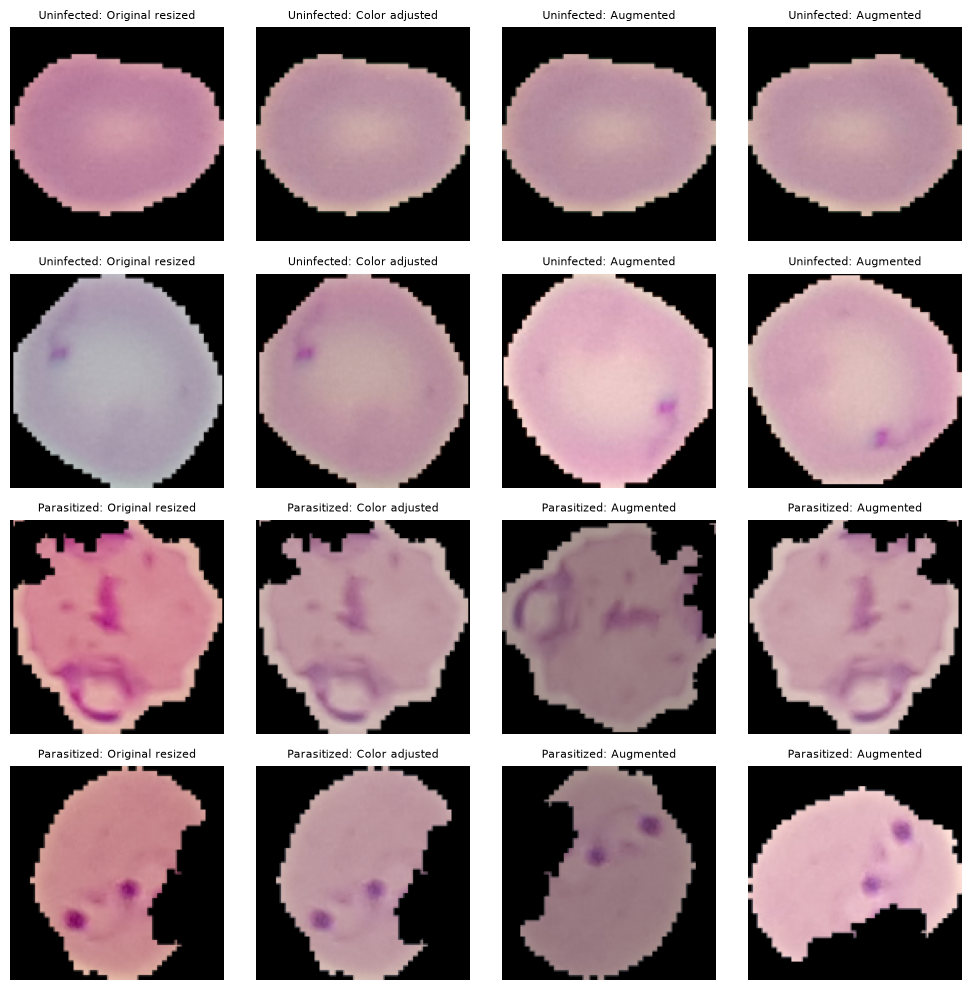

In [15]:
fig, axes = plt.subplots(4,4,figsize=(10,10))
examples = pd.concat([parts['train'].query('label == 0').sample(2,random_state=SEED), parts['train'].query('label == 1').sample(2,random_state=SEED)])
rng = np.random.default_rng(SEED)
for axes_row, row in zip(axes, examples.itertuples()):
    raw = load_rgb(row.path)
    corrected = correct_color(raw)
    views = [raw, corrected, augment(corrected,rng), augment(corrected,rng)]
    for ax, image, title in zip(axes_row, views, ['Original resized','Color adjusted','Augmented','Augmented']):
        ax.imshow(image); ax.set_title(f'{row.class_name}: {title}',fontsize=8); ax.axis('off')
plt.tight_layout()
plt.savefig(OUT / 'training_preview.png',dpi=150)
plt.show()

### 3.2 Included features, exclusions, and prediction
- **CNN:** 128 x 128 x 3 standardized RGB input values (49,152 values); the CNN will learn spatial, texture and color features during later model training.
- **SVM:** 1,764 grayscale HOG orientation/edge features plus 48 foreground RGB histogram features (16 bins/channel), total **1,812**. Fit `StandardScaler` on training feature vectors only, then apply it to validation/test. No scaler or classifier is fitted here.
- **Prediction:** the cell's parasitized (1) versus uninfected (0) label, not the patient's infection status.

These are preparation results, **not evidence of improved model accuracy**. Train the SVM and CNN on the same patient partitions. Use validation accuracy, F1, precision, recall/sensitivity, specificity, balanced accuracy, ROC-AUC and a confusion matrix to compare the models and augmentation off vs on. Color normalization is applied to all model inputs. Inspect false positives/negatives, especially parasite detail lost by normalization or resizing. Tune preprocessing and thresholds on validation only, then freeze choices and evaluate test once. If small parasites disappear, consider higher resolution; if color transfer erases stain cues, consider a gentler normalization method. Patient-level grouped cross-validation inside training is appropriate for further tuning. The observed class proportions are close to 50/50, so class weighting is unnecessary for this split. Do not claim a modification improved performance until those experiments are run.